# 2. Erronka – Smart Environment AI: Ikaskuntza automatikoen sistemak (SAA)

**Modulua:** Ikaskuntza automatikoen sistemak · **Zikloa:** IA eta Big Data (FP Santurtzi)

## 1. Sarrera

Koaderno honetan PIA zatian prestatu ditugun **Mundakako airearen kalitate-datuekin** (Bizkaiko Foru Aldundia) makina-ikaskuntzako ereduak entrenatuko ditugu. Hauek egingo ditugu:

1. Datuak ordena kronologikoan *train*/*test* multzoetan banatu eta aurreprozesamendua *pipeline* baten barruan erabili.
2. **Erregresioa:** PM10 aurreikusi (erregresio lineal sinplea eta anizkoitza, Ridge eta Lasso), hiperparametroak balidazioarekin doitu eta MAE, RMSE eta R²-rekin konparatu.
3. **Sailkapena:** airearen kalitate-kategoriak sortu eta KNN, erabaki-zuhaitza eta Naive Bayes konparatu (nahasmen-matrizea, precision, recall eta F1).
4. **Gainbegiratu gabeko ikaskuntza:** K-means aplikatu, *k* aukeratu (elbow eta silhouette) eta klusterrak interpretatu.
5. Eredurik onena aukeratu, idatziz justifikatu, gorde eta datu berriekin probatu.

## 2. Datuen prestaketa

Datuak PIAn bezala kargatzen ditugu (`;` bereizlea, `latin1` kodeketa, datak `DD/MM/YYYY`), `Month` eta `DayOfWeek` sortzen ditugu eta `O3 8h` zutabea kentzen dugu (%31 huts).

Aurreprozesamendua funtzio batean jarri dugu, eredu bakoitzak berea izan dezan: aldagai zenbakizkoetan mediana (`SimpleImputer`) eta estandarizazioa (`StandardScaler`), eta `Month` eta `DayOfWeek` aldagaietan *one-hot*. Hemen **PCA ez dugu erabiltzen**: osagai nagusiek jatorrizko aldagaiak ezkutatzen dituzte, eta guk erregresioaren koefizienteak interpretatu nahi ditugu. Aurreprozesamendua *pipeline*-aren barruan doanez, *train* multzoarekin bakarrik doitzen da (*data leakage* saihesteko).

**Ebaluazio-estrategia.** Datuak denbora-serie bat dira: egun jarraituak oso antzekoak dira, eta ausazko banaketak *test*-eko egunen "bizilagunak" sartuko lituzke entrenamenduan. Horregatik:

- **Entrenamendua (lehen %80) eta proba (azken %20)**, ordena kronologikoan.
- **Balidazioa:** `TimeSeriesSplit` (5 zati) entrenamenduko datuen barruan. Hiperparametroak eta eredua balidazioarekin aukeratzen ditugu; *test* multzoa behin bakarrik erabiltzen dugu, azken ebaluaziorako.

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score, make_scorer)
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore', message='KMeans is known to have a memory leak')

# Datuen karga (PIA zatiko pauso berberak)
df = pd.read_csv('MUNDAKA.csv', sep=';', encoding='latin1')
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values('Date').reset_index(drop=True)

# Ezaugarri tenporalak eta O3 8h zutabea kendu (%31 huts)
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df = df.drop(columns=['O3 8h (µg/m3)'])

print(df.shape)
print(df.isnull().sum())

(306, 9)
Date              0
NO (µg/m3)        4
NOX (µg/m3)       4
NO2 (µg/m3)       4
O3 (µg/m3)        2
PM10 (µg/m3)     49
PM2,5 (µg/m3)     2
Month             0
DayOfWeek         0
dtype: int64


In [2]:
# Aurreprozesamendua (PIAn erabilitakoaren berdina, PCA gabe)
def sortu_aurreprozesamendua(zenbakizkoak, kategorikoak):
    return ColumnTransformer(transformers=[
        ('zenbakizkoak', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                   ('scaler', StandardScaler())]), zenbakizkoak),
        ('kategorikoak', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kategorikoak)
    ])

kategorikoak = ['Month', 'DayOfWeek']

## 3. Erregresioa: PM10 aurreikustea

**PM10**-en kontzentrazioa kalkulatuko dugu egun bereko gainerako kutsatzaileekin eta denbora-aldagaiekin. PM10 hutsik duten 49 errenkadak kentzen ditugu, helburuaren balioak ez ditugulako asmatu nahi.

Lau eredu konparatuko ditugu:

- **Erregresio lineal sinplea:** `PM2,5` aldagai bakarrarekin (PM10-ekin korrelaziorik handiena duena, ≈ 0,83).
- **Erregresio lineal anizkoitza:** ezaugarri guztiekin.
- **Ridge** eta **Lasso:** erregularizazioarekin; `alpha` balidazioarekin aukeratzen dugu (`GridSearchCV`).

Ausazko banaketaren R²-a ere erakusten dugu, ebaluazio-moduak emaitzetan duen eragina ikusteko. Ez dugu eredua aukeratzeko erabiltzen.

In [3]:
# Helburua: PM10. Ezaugarriak: gainerako kutsatzaileak + denbora-aldagaiak
zenb_erreg = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM2,5 (µg/m3)']
df_erreg = df.dropna(subset=['PM10 (µg/m3)'])
X_erreg = df_erreg[zenb_erreg + kategorikoak]
y_erreg = df_erreg['PM10 (µg/m3)']

# Banaketa kronologikoa: lehen %80 entrenatzeko, azken %20 probatzeko
muga = int(len(X_erreg) * 0.8)
X_tr, X_te = X_erreg.iloc[:muga], X_erreg.iloc[muga:]
y_tr, y_te = y_erreg.iloc[:muga], y_erreg.iloc[muga:]
print(f"Train: {X_tr.shape[0]} errenkada ({df_erreg['Date'].iloc[0].date()} - {df_erreg['Date'].iloc[muga-1].date()})")
print(f"Test: {X_te.shape[0]} errenkada ({df_erreg['Date'].iloc[muga].date()} - {df_erreg['Date'].iloc[-1].date()})")

Train: 205 errenkada (2026-01-01 - 2026-09-08)
Test: 52 errenkada (2026-09-09 - 2026-11-02)


In [4]:
# Hiperparametroak balidazioarekin doitu (TimeSeriesSplit), eta azkenean test multzoan ebaluatu
balidazioa = TimeSeriesSplit(n_splits=5)
alpha_balioak = np.logspace(-3, 2, 11)

# Eredua: (algoritmoa, zenbakizko aldagaiak, kategorikoak, probatu beharreko hiperparametroak)
ereduak_erreg = {
    'Erregresio lineal sinplea': (LinearRegression(), ['PM2,5 (µg/m3)'], [], {}),
    'Erregresio lineal anizkoitza': (LinearRegression(), zenb_erreg, kategorikoak, {}),
    'Ridge': (Ridge(), zenb_erreg, kategorikoak, {'eredua__alpha': alpha_balioak}),
    'Lasso': (Lasso(max_iter=20000), zenb_erreg, kategorikoak, {'eredua__alpha': alpha_balioak}),
}

# Ausazko banaketa, konparaziorako bakarrik
X_aus_tr, X_aus_te, y_aus_tr, y_aus_te = train_test_split(X_erreg, y_erreg, test_size=0.2, random_state=42)

emaitzak_erreg, pipe_erreg = [], {}
for izena, (eredua, zenb, kat, parametroak) in ereduak_erreg.items():
    pipe = Pipeline([('aurre', sortu_aurreprozesamendua(zenb, kat)), ('eredua', eredua)])
    bilaketa = GridSearchCV(pipe, parametroak, cv=balidazioa, scoring='neg_root_mean_squared_error')
    bilaketa.fit(X_tr[zenb + kat], y_tr)
    pipe_erreg[izena] = bilaketa.best_estimator_
    iragarpena = bilaketa.predict(X_te[zenb + kat])
    pipe_aus = clone(bilaketa.best_estimator_).fit(X_aus_tr[zenb + kat], y_aus_tr)
    emaitzak_erreg.append({
        'Eredua': izena,
        'Alpha': bilaketa.best_params_.get('eredua__alpha', np.nan),
        'Balidazio RMSE': -bilaketa.best_score_,
        'MAE': mean_absolute_error(y_te, iragarpena),
        'RMSE': np.sqrt(mean_squared_error(y_te, iragarpena)),
        'R²': r2_score(y_te, iragarpena),
        'R² (ausazkoa)': r2_score(y_aus_te, pipe_aus.predict(X_aus_te[zenb + kat]))
    })

emaitzak_erreg = pd.DataFrame(emaitzak_erreg).set_index('Eredua').round(3)
display(emaitzak_erreg)

# Eredu onena balidazioaren arabera aukeratzen dugu, ez test multzoaren arabera
eredu_onena = emaitzak_erreg['Balidazio RMSE'].idxmin()
print(f"Eredu onena (balidazioa): {eredu_onena}")

# Lasso-k zenbat koefiziente utzi dituen zeroan
lasso_koef = pipe_erreg['Lasso'].named_steps['eredua'].coef_
print(f"Lasso: {(lasso_koef == 0).sum()} koefiziente zeroan, {len(lasso_koef)} guztira")

,Alpha,Balidazio RMSE,MAE,RMSE,R²,R² (ausazkoa)
Eredua,,,,,,
Erregresio lineal sinplea,NaN,2.896,1.925,2.602,0.262,0.705
Erregresio lineal anizkoitza,NaN,3.222,1.891,2.598,0.264,0.673
Ridge,31.623,2.729,1.817,2.415,0.364,0.753
Lasso,1.000,2.799,1.846,2.403,0.371,0.687


Eredu onena (balidazioa): Ridge
Lasso: 19 koefiziente zeroan, 21 guztira


**Emaitzen irakurketa:**

- **Ridge da onena balidazioan** (RMSE ≈ 2,73), eta horregatik aukeratzen dugu. *Test* multzoan MAE ≈ 1,82 µg/m³, RMSE ≈ 2,42 µg/m³ eta R² ≈ 0,36 lortzen ditu. Lasso-k *test*-ean apur bat hobeto egiten du (R² ≈ 0,37), baina aldea oso txikia da eta ez dugu *test* multzoa eredua aukeratzeko erabiltzen.
- **Erregresio anizkoitza da okerrena balidazioan** (RMSE ≈ 3,22). Ezaugarri asko ditu (*one-hot*-ekin 21 zutabe) 205 entrenamendu-errenkadarentzat, eta batzuk elkarren artean oso lotuta daude (NO, NOX, NO2). Horregatik laguntzen du erregularizazioak. Lasso-k 21 koefizienteetatik 19 zeroan utzi ditu.
- **Ebaluazio-moduak asko eragiten du:** ausazko banaketarekin Ridge-k R² ≈ 0,75 lortzen du, eta kronologikoarekin R² ≈ 0,36. Ausazko emaitza baikorregia da: egun jarraituak oso antzekoak direnez, *test*-eko egunen informazioa ia entrenamenduan dago. Kronologikoa da errealitatetik gertuen dagoena, eredua etorkizuneko egunetan erabiliko baitugu.
- **Mugak:** *test* multzoak iraileko bigarren astetik azarora arteko 52 egun ditu, eta urriko eta azaroko daturik ez dago entrenamenduan. Urte bakarreko datuak ditugunez, ereduak ezin du urtaro hori ikasi.

### 3.1. Biharko PM10-a aurreikustea

Goiko ereduek egun bereko neurketak behar dituzte, beraz PM10-a **kalkulatzen** dute, ez etorkizuna iragartzen. Benetako aurreikuspena probatzeko, **biharko PM10-a** iragarriko dugu gaurko eta atzoko datuekin, eta eredu "naif" batekin konparatuko dugu: bihar gaurko balio bera izango dela suposatzea.

In [5]:
# Helburua: biharko PM10-a. Ezaugarriak: gaurko kutsatzaileak, gaurko eta atzoko PM10-a
df_bihar = df.copy()
df_bihar['PM10 bihar'] = df_bihar['PM10 (µg/m3)'].shift(-1)
df_bihar['PM10 atzo'] = df_bihar['PM10 (µg/m3)'].shift(1)
df_bihar = df_bihar.dropna(subset=['PM10 bihar'])
zenb_bihar = zenb_erreg + ['PM10 (µg/m3)', 'PM10 atzo']

muga_b = int(len(df_bihar) * 0.8)
bihar_tr, bihar_te = df_bihar.iloc[:muga_b], df_bihar.iloc[muga_b:]

pipe_bihar = Pipeline([('aurre', sortu_aurreprozesamendua(zenb_bihar, ['Month'])), ('eredua', Ridge())])
bilaketa_b = GridSearchCV(pipe_bihar, {'eredua__alpha': alpha_balioak}, cv=balidazioa,
                          scoring='neg_root_mean_squared_error')
bilaketa_b.fit(bihar_tr[zenb_bihar + ['Month']], bihar_tr['PM10 bihar'])

# Bi ereduak egun berdinekin konparatu (gaurko PM10-a ezagutzen den egunak)
te = bihar_te.dropna(subset=['PM10 (µg/m3)'])
pred_ridge = bilaketa_b.predict(te[zenb_bihar + ['Month']])
pred_naif = te['PM10 (µg/m3)']
display(pd.DataFrame([
    {'Eredua': 'Ridge', 'MAE': mean_absolute_error(te['PM10 bihar'], pred_ridge),
     'RMSE': np.sqrt(mean_squared_error(te['PM10 bihar'], pred_ridge)), 'R²': r2_score(te['PM10 bihar'], pred_ridge)},
    {'Eredua': 'Naif (gaurko balioa)', 'MAE': mean_absolute_error(te['PM10 bihar'], pred_naif),
     'RMSE': np.sqrt(mean_squared_error(te['PM10 bihar'], pred_naif)), 'R²': r2_score(te['PM10 bihar'], pred_naif)}
]).set_index('Eredua').round(3))
print(f"Test: {len(te)} egun")

,MAE,RMSE,R²
Eredua,,,
Ridge,2.623,3.060,-0.027
Naif (gaurko balioa),2.469,3.191,-0.117


Test: 49 egun


**Emaitzen irakurketa:** bi ereduek R² ≈ 0 inguruan dute (Ridge -0,03, naifa -0,12), hau da, ez dira beti batezbestekoa iragartzea baino hobeak. Ridge-k RMSE hobea du (3,06 vs 3,19), baina MAE okerragoa (2,62 vs 2,47). **Beraz, datu hauekin ezin dugu biharko PM10-a modu erabilgarrian aurreikusi.** Horretarako meteorologia-aldagaiak (haizea, euria, presioa) eta urte gehiagoko datuak beharko lirateke. Horregatik, 3. ataleko eredua **egun bereko PM10-a kalkulatzeko** erabiliko dugu.

## 4. Sailkapena: airearen kalitate-kategoriak

### 4.1. Kategoriak sortzea

Datuetan ez dago kalitate-kategoriarik, beraz guk sortu behar dugu. **O3**-ren eguneko batezbestekoa erabiltzen dugu (kutsatzaile nagusia delako Mundakan) eta lau kategoria definitzen ditugu, enuntziatuan datozenak:

| Kategoria | O3 (µg/m³) |
|---|---|
| Ona | < 60 |
| Onargarria | 60 – 75 |
| Txarra | 75 – 90 |
| Oso txarra | ≥ 90 |

**Garrantzitsua:** kategoria hauek **erlatiboak** dira, Mundakako egunak beren artean konparatzen dituzte, eta **ez dute osasun-arriskurik adierazten**. Ofizialki (ICA indizea, MITECO), O3-k "Ona" 0-50 µg/m³ artean du eta "Nahiko ona" 51-100 µg/m³ artean. Beheko kodeak erakusten du zer gertatuko litzatekeen atalase ofizialekin (ICAk 8 orduko batezbesteko mugikorra erabiltzen du; hemen eguneko batezbestekoa dugu, beraz konparazioa gutxi gorabeherakoa da). Ia egun guztiak kategoria berean daudenez, atalase ofizialekin ezin da sailkatzailerik entrenatu; horregatik erabiltzen ditugu erlatiboak. Herritarrentzako alertetan atalase ofizialak erabili beharko lirateke.

Kategoria O3-rekin sortu dugunez, **O3 ez dugu ezaugarrien artean sartzen** (bestela eredua kategoria definitzen duen arau bera ikasiko luke eta emaitza faltsua izango litzateke).

In [6]:
# Airearen kalitate-kategoriak O3-ren arabera (atalase erlatiboak, gure datuetara egokituak)
def kategoria_sortu(o3):
    if o3 < 60:
        return 'Ona'
    elif o3 < 75:
        return 'Onargarria'
    elif o3 < 90:
        return 'Txarra'
    else:
        return 'Oso txarra'

kategoria_ordena = ['Ona', 'Onargarria', 'Txarra', 'Oso txarra']

df_sail = df.dropna(subset=['O3 (µg/m3)']).copy()
df_sail['Kalitatea'] = df_sail['O3 (µg/m3)'].apply(kategoria_sortu)
print(df_sail['Kalitatea'].value_counts().reindex(kategoria_ordena))

# Konparaziorako: egun kopurua ICA atalase ofizialen arabera
ica = pd.cut(df_sail['O3 (µg/m3)'], bins=[-1, 50, 100, 130, 240],
             labels=['Ona (0-50)', 'Nahiko ona (51-100)', 'Erregularra (101-130)', 'Txarra (131-240)'])
print("\nICA ofiziala (O3):")
print(ica.value_counts().sort_index())

# O3 ezaugarrietatik kentzen dugu, kategoria berarekin sortu delako (data leakage)
zenb_sail = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'PM10 (µg/m3)', 'PM2,5 (µg/m3)']
X_sail = df_sail[zenb_sail + kategorikoak]
y_sail = df_sail['Kalitatea']

# Banaketa kronologikoa (erregresioan bezala)
muga_s = int(len(X_sail) * 0.8)
Xs_tr, Xs_te = X_sail.iloc[:muga_s], X_sail.iloc[muga_s:]
ys_tr, ys_te = y_sail.iloc[:muga_s], y_sail.iloc[muga_s:]
print("\nTrain:", ys_tr.value_counts().reindex(kategoria_ordena).to_dict())
print("Test:", ys_te.value_counts().reindex(kategoria_ordena).to_dict())

Kalitatea
Ona            64
Onargarria    112
Txarra        101
Oso txarra     27
Name: count, dtype: int64

ICA ofiziala (O3):
O3 (µg/m3)
Ona (0-50)                24
Nahiko ona (51-100)      275
Erregularra (101-130)      5
Txarra (131-240)           0
Name: count, dtype: int64

Train: {'Ona': 34, 'Onargarria': 90, 'Txarra': 95, 'Oso txarra': 24}
Test: {'Ona': 30, 'Onargarria': 22, 'Txarra': 6, 'Oso txarra': 3}


### 4.2. Ereduak entrenatu eta konparatu

KNN, erabaki-zuhaitza eta Naive Bayes entrenatzen ditugu. KNN-ren auzokide kopurua eta zuhaitzaren sakonera balidazioarekin aukeratzen ditugu. Metriketan `macro` batezbestekoa erabiltzen dugu: kategoriak ez daude orekatuta, eta horrela kategoria bakoitzak pisu bera du. Ausazko banaketaren *accuracy*-a ere erakusten dugu, konparaziorako bakarrik.

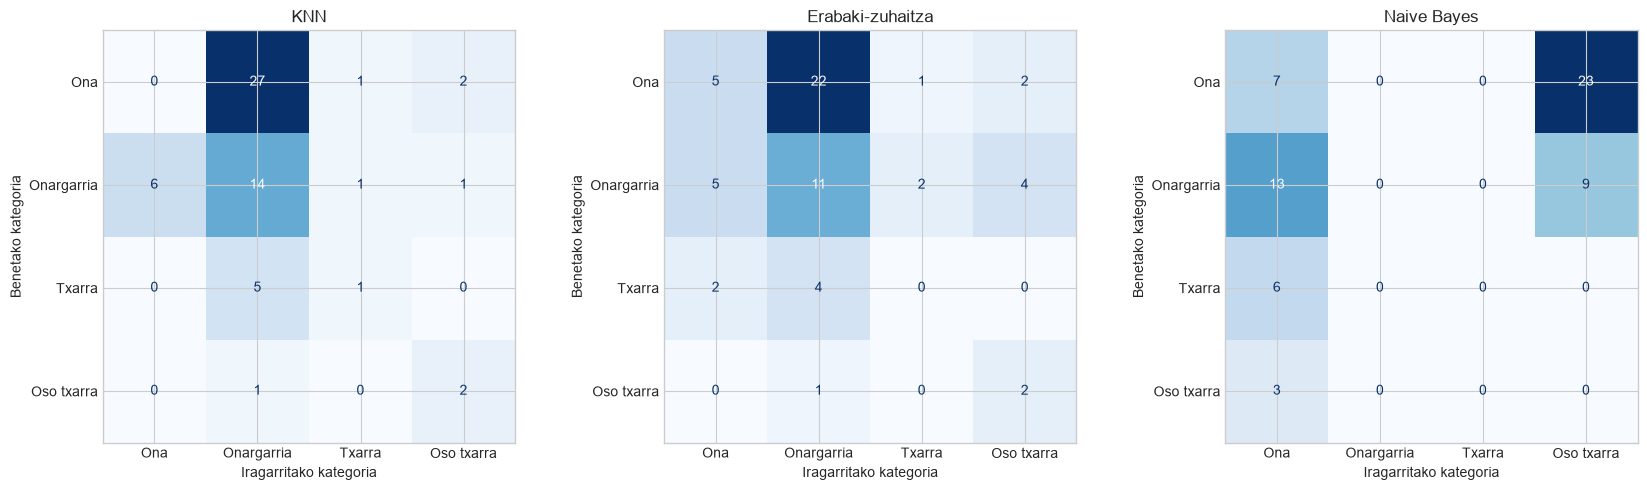

,Parametroak,Balidazio F1,Accuracy,Precision,Recall,F1,Accuracy (ausazkoa)
Eredua,,,,,,,
KNN,{'n_neighbors': 9},0.325,0.279,0.258,0.367,0.282,0.607
Erabaki-zuhaitza,{'max_depth': 8},0.288,0.295,0.239,0.333,0.242,0.525
Naive Bayes,{},0.190,0.115,0.060,0.058,0.059,0.295


Erreferentzia (klase nagusia): Txarra | accuracy 0.098 | F1 0.045


In [7]:
f1_macro = make_scorer(f1_score, average='macro', zero_division=0)

ereduak_sail = {
    'KNN': (KNeighborsClassifier(), {'eredua__n_neighbors': list(range(1, 32, 2))}),
    'Erabaki-zuhaitza': (DecisionTreeClassifier(random_state=42), {'eredua__max_depth': list(range(2, 9))}),
    'Naive Bayes': (GaussianNB(), {})
}

# Ausazko banaketa, konparaziorako bakarrik
Xs_aus_tr, Xs_aus_te, ys_aus_tr, ys_aus_te = train_test_split(
    X_sail, y_sail, test_size=0.2, random_state=42, stratify=y_sail)

emaitzak_sail = []
fig, ardatzak = plt.subplots(1, 3, figsize=(17, 5))
for ardatza, (izena, (eredua, parametroak)) in zip(ardatzak, ereduak_sail.items()):
    pipe = Pipeline([('aurre', sortu_aurreprozesamendua(zenb_sail, kategorikoak)), ('eredua', eredua)])
    bilaketa = GridSearchCV(pipe, parametroak, cv=balidazioa, scoring=f1_macro)
    bilaketa.fit(Xs_tr, ys_tr)
    iragarpena = bilaketa.predict(Xs_te)
    pipe_aus = clone(bilaketa.best_estimator_).fit(Xs_aus_tr, ys_aus_tr)
    emaitzak_sail.append({
        'Eredua': izena,
        'Parametroak': str({k.replace('eredua__', ''): v for k, v in bilaketa.best_params_.items()}),
        'Balidazio F1': bilaketa.best_score_,
        'Accuracy': accuracy_score(ys_te, iragarpena),
        'Precision': precision_score(ys_te, iragarpena, average='macro', zero_division=0),
        'Recall': recall_score(ys_te, iragarpena, average='macro', zero_division=0),
        'F1': f1_score(ys_te, iragarpena, average='macro', zero_division=0),
        'Accuracy (ausazkoa)': accuracy_score(ys_aus_te, pipe_aus.predict(Xs_aus_te))
    })
    ConfusionMatrixDisplay(confusion_matrix(ys_te, iragarpena, labels=kategoria_ordena),
                           display_labels=kategoria_ordena).plot(ax=ardatza, cmap='Blues', colorbar=False)
    ardatza.set_title(izena)
    ardatza.set_xlabel('Iragarritako kategoria')
    ardatza.set_ylabel('Benetako kategoria')
plt.tight_layout()
plt.show()

emaitzak_sail = pd.DataFrame(emaitzak_sail).set_index('Eredua').round(3)
display(emaitzak_sail)

# Erreferentzia: beti entrenamenduko klase nagusia iragartzea
dummy = DummyClassifier(strategy='most_frequent').fit(Xs_tr, ys_tr)
iragarpen_dummy = dummy.predict(Xs_te)
print(f"Erreferentzia (klase nagusia): {dummy.classes_[np.argmax(dummy.class_prior_)]}"
      f" | accuracy {accuracy_score(ys_te, iragarpen_dummy):.3f}"
      f" | F1 {f1_score(ys_te, iragarpen_dummy, average='macro', zero_division=0):.3f}")

**Emaitzen irakurketa:**

- **KNN da onena balidazioan** (F1 ≈ 0,33, k = 9), baina emaitzak **ez dira onak**: *test*-ean accuracy ≈ 0,28 eta F1 ≈ 0,28. Erreferentzia baino hobea da (accuracy ≈ 0,10, F1 ≈ 0,05), baina ez da nahikoa benetan erabiltzeko.
- **Erabaki-zuhaitza** antzekoa da (accuracy ≈ 0,30, F1 ≈ 0,24) eta **Naive Bayes** okerrena (accuracy ≈ 0,12). Naive Bayes-ek aldagaiak elkarrekiko independenteak direla suposatzen du, eta hemen NO, NOX eta NO2 oso lotuta daude; gainera *one-hot* aldagaiak ez datoz ondo bat banaketa normalarekin.
- **Zergatik da zaila?** O3 gainerako kutsatzaileekin ia ez dago lotuta (O3 eta NOX artean korrelazioa ≈ 0,02) eta urtaroaren araberakoa da. Entrenamenduan "Txarra" da kategoria ohikoena (243tik 95), baina *test*-ean, udazkenean, "Ona" da (61etik 30). Urriko eta azaroko daturik ez dagoenez entrenamenduan, `Month` aldagaiak ere ezin du lagundu.
- **Ausazko banaketak hau ezkutatzen du:** KNN-k accuracy ≈ 0,61 lortuko luke horrela, *test*-ean urtaro guztietako egunak daudelako.
- **"Oso txarra" kategoriak 3 adibide baino ez ditu *test* multzoan**, beraz kategoria horren emaitzak ez dira fidagarriak.

## 5. Gainbegiratu gabeko ikaskuntza: K-means

Ingurumen-patroiak (egun-motak) aurkitzeko K-means erabiltzen dugu kutsatzaile guztiekin (NO, NOX, NO2, O3, PM10 eta PM2,5), mediana-imputazioa eta estandarizazioa aplikatuta. `Month` ez dugu sartzen, gero kluster bakoitzean zer hilabetetan agertzen den ikusteko.

*k* aukeratzeko bi metodo erabiltzen ditugu: **elbow** (inertzia) eta **silhouette**.

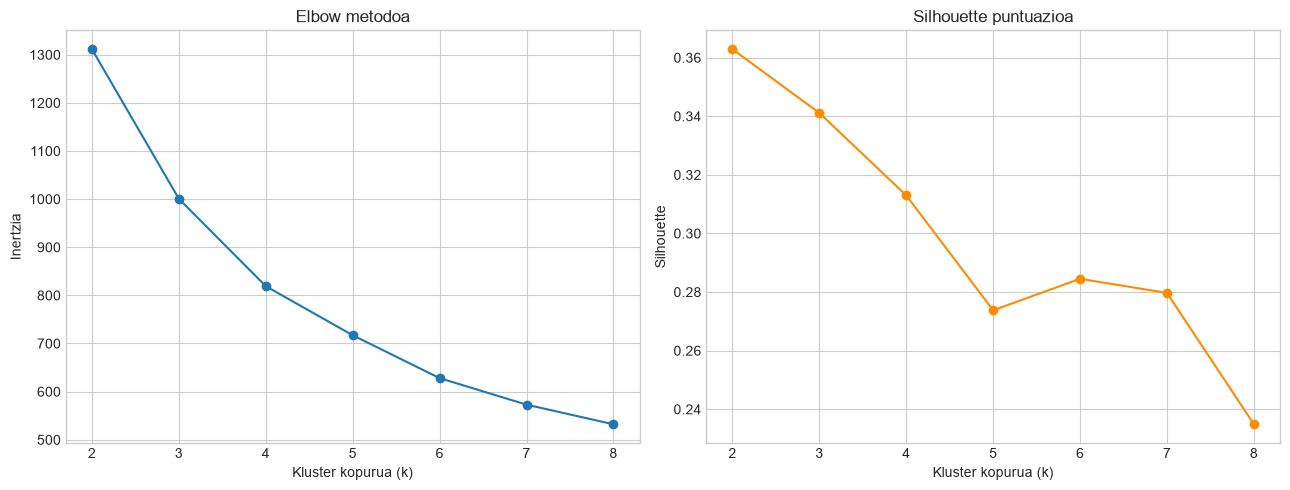

{2: np.float64(0.363), 3: np.float64(0.341), 4: np.float64(0.313), 5: np.float64(0.274), 6: np.float64(0.285), 7: np.float64(0.28), 8: np.float64(0.235)}


In [8]:
# K-means: kutsatzaile-aldagaiekin (hilabetea ez dugu sartzen, gero kluster bakoitzean aztertzeko)
zenb_klust = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM10 (µg/m3)', 'PM2,5 (µg/m3)']
df_klust = df.dropna(subset=zenb_klust, how='all').copy()

aurre_klust = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
X_klust = aurre_klust.fit_transform(df_klust[zenb_klust])

# k aukeratzeko: elbow (inertzia) eta silhouette
k_balioak = range(2, 9)
inertziak, silhouetteak = [], []
for k in k_balioak:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_klust)
    inertziak.append(km.inertia_)
    silhouetteak.append(silhouette_score(X_klust, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
a1.plot(list(k_balioak), inertziak, marker='o')
a1.set_title('Elbow metodoa')
a1.set_xlabel('Kluster kopurua (k)')
a1.set_ylabel('Inertzia')
a2.plot(list(k_balioak), silhouetteak, marker='o', color='darkorange')
a2.set_title('Silhouette puntuazioa')
a2.set_xlabel('Kluster kopurua (k)')
a2.set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

print(dict(zip(k_balioak, np.round(silhouetteak, 3))))

In [9]:
# k = 2 eta k = 3 konparatu: bi aukerak interpretatzeko
km2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_klust)
print("k = 2 - egun kopurua:", np.bincount(km2.labels_))
display(df_klust.groupby(km2.labels_)[zenb_klust].mean().round(1))

k = 2 - egun kopurua: [228  76]


,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),PM10 (µg/m3),"PM2,5 (µg/m3)"
0,0.3,3.0,2.5,69.3,10.1,4.6
1,0.9,5.7,4.6,78.0,16.5,8.9


**k aukeraketa:** silhouette puntuaziorik handiena *k* = 2 da (0,36), baina *k* = 3 oso gertu dago (0,34). Elbow grafikoan ez dago "ukondo" argirik, inertzia pixkanaka jaisten da. **k = 3 aukeratu dugu**, interpretazio hobea ematen duelako: goiko taulan, *k* = 2-ren bigarren taldeak (76 egun) NOX altuko egunak eta O3 eta partikula altuko egunak nahasten ditu, eta *k* = 3-rekin bi egun-mota horiek bereizita geratzen dira.

In [10]:
K_AUKERATUA = 3   # goiko bi grafikoen arabera aukeratua

km = KMeans(n_clusters=K_AUKERATUA, random_state=42, n_init=10).fit(X_klust)
df_klust['Klusterra'] = km.labels_

# Kluster bakoitzaren batezbestekoak (interpretaziorako)
print("Kluster bakoitzeko egun kopurua:")
print(df_klust['Klusterra'].value_counts().sort_index())
display(df_klust.groupby('Klusterra')[zenb_klust].mean().round(1))

# Kluster bakoitzeko hilabeteak
display(pd.crosstab(df_klust['Klusterra'], df_klust['Month']))

Kluster bakoitzeko egun kopurua:
Klusterra
0     60
1    200
2     44
Name: count, dtype: int64


,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),PM10 (µg/m3),"PM2,5 (µg/m3)"
Klusterra,,,,,,
0,1.2,6.3,4.6,67.5,10.9,4.8
1,0.2,2.8,2.4,68.8,10.1,4.7
2,0.3,4.3,3.9,88.8,19.8,11.4


Month,1,2,3,4,5,6,7,8,9,10,11
Klusterra,,,,,,,,,,,
0,17,12,14,5,0,0,0,0,5,6,1
1,14,15,10,20,23,23,19,30,20,25,1
2,0,1,7,5,8,7,12,0,4,0,0


**Klusterren interpretazioa:**

- **0. klusterra (60 egun) – NOx altuko egunak:** NO, NOX eta NO2 beste klusterretan baino altuagoak dira (NOX ≈ 6,3 µg/m³) eta O3 ez da altua. Egun gehienak urtarriletik martxora eta irailetik azarora daude. Hipotesi gisa, trafikoak edo berokuntzak sortutako kutsadura izan daiteke, hedapen txarreko egunetan pilatua. Hori ezin dugu datu hauekin ziurtatu.
- **1. klusterra (200 egun) – aire garbiko egunak:** kutsatzaile guztiak baxuak dira (NOX ≈ 2,8 µg/m³, PM10 ≈ 10 µg/m³) eta urte osoan zehar agertzen dira. Mundakako egun "normalak" dira.
- **2. klusterra (44 egun) – O3 eta partikula altuko egunak:** O3 (≈ 89 µg/m³), PM10 (≈ 20 µg/m³) eta PM2,5 (≈ 11 µg/m³) altuenak dira. Ia guztiak udaberrian eta udan daude (martxotik irailera). Kutsadura-episodio puntualen seinale izan daiteke, PIA zatiko EDA-n ikusitako ekainaren amaierako pikoen modukoak.

### 5.1. K-means eredua gorde

K-means eredua ere gordetzen dugu (`kmeans_eredua.pkl`), aurreprozesamenduarekin batera, dashboard-ean egun berri bakoitzaren klusterra erakutsi ahal izateko. Azken egunarekin probatzen dugu.

In [11]:
# Aurreprozesamendua eta K-means pipeline bakarrean (biak goian doituta daude)
klust_pipeline = Pipeline([('aurre', aurre_klust), ('kmeans', km)])
joblib.dump(klust_pipeline, 'kmeans_eredua.pkl')

kluster_izenak = {0: 'NOx altuko egunak', 1: 'Aire garbiko egunak', 2: 'O3 eta partikula altuko egunak'}
kargatua_klust = joblib.load('kmeans_eredua.pkl')
azken_eguna = df_klust.iloc[[-1]]
klusterra = kargatua_klust.predict(azken_eguna[zenb_klust])[0]
print(f"Eguna: {azken_eguna['Date'].iloc[0].date()} | Klusterra: {klusterra} ({kluster_izenak[klusterra]})")

Eguna: 2026-11-02 | Klusterra: 0 (NOx altuko egunak)


## 6. Eredurik onena aukeratu eta justifikatu

**Aukeratutako eredua: Ridge erregresioa (alpha ≈ 31,6), egun bereko PM10-a kalkulatzeko.**

Arrazoiak:

1. **Balidazioan onena da** (RMSE ≈ 2,73), eta *test* multzoan MAE ≈ 1,82 µg/m³ eta R² ≈ 0,36 lortzen ditu. Eredua balidazioarekin aukeratu dugu, ez *test*-arekin.
2. **Erregularizazioak overfitting-a murrizten du:** erregresio anizkoitzak baino hobeto dabil datu gutxirekin (205 errenkada) eta aldagai korrelatuekin.
3. **Erabilgarria da:** PM10 neurgailuak 49 egunetan ez du daturik eman, eta eredu honek balio horiek gainerako neurketekin kalkula ditzake.
4. **Arina da:** eredu lineal bat da, eta horrek **Jetson Nano**-n exekutatzeko abantaila bat dakar (memoria eta denbora gutxi).

Sailkapen-ereduak baztertu ditugu, **O3-ren kategoria aurreikustea ez baita ondo ateratzen** gure ezaugarriekin (KNN: accuracy ≈ 0,28). K-means ez dugu konparatzen, ez baita ikaskuntza gainbegiratua, baina oso baliagarria izan da kutsadura-egun motak identifikatzeko.

**Mugak:**

- R² ≈ 0,36 apala da: ereduak PM10-aren aldakortasunaren zati bat bakarrik azaltzen du.
- Eredua ez da benetako aurreikuspena: egun bereko neurketak behar ditu, eta biharko PM10-a iragartzeko probak ez du emaitza erabilgarririk eman (3.1. atala).
- Datu gutxi ditugu: estazio bakarra, eguneko datuak eta 306 egun, 2026koak bakarrik. Hobetzeko, urte gehiagoko datuak, estazio gehiago eta meteorologia-aldagaiak beharko genituzke.

### 6.1. Eredua gorde eta datu berriekin probatu

Aukeratutako *pipeline*-a (aurreprozesamendua + eredua) `joblib`-ekin gordetzen dugu. Gero berriro kargatzen dugu eta entrenamenduan erabili ez den egun erreal batekin probatzen dugu: datu-multzoko azken eguna.

In [12]:
# Pipeline osoa gorde eta berriro kargatu
fitxategia = 'pm10_eredua.pkl'
joblib.dump(pipe_erreg[eredu_onena], fitxategia)
kargatua = joblib.load(fitxategia)

# Egun berria: pipeline-ak datu gordinak hartzen ditu (hutsuneak barne)
egun_berria = df_erreg.iloc[[-1]]
iragarpena = kargatua.predict(egun_berria[zenb_erreg + kategorikoak])[0]
print(f"Eredua: {eredu_onena} | Eguna: {egun_berria['Date'].iloc[0].date()}")
print(f"Iragarritako PM10: {iragarpena:.1f} µg/m³ | Benetakoa: {egun_berria['PM10 (µg/m3)'].iloc[0]:.1f} µg/m³")

Eredua: Ridge | Eguna: 2026-11-02
Iragarritako PM10: 9.8 µg/m³ | Benetakoa: 8.0 µg/m³


## 7. Iturriak

- Datuak: [Open Data Euskadi](https://opendata.euskadi.eus), Euskadiko airearen kalitatearen sarea (Mundaka estazioa).
- Airearen kalitatearen indizea (ICA): [MITECO](https://www.miteco.gob.es/es/calidad-y-evaluacion-ambiental/temas/atmosfera-y-calidad-del-aire/visualizacion-datos-calidad-del-aire/ica.html).
- [scikit-learn dokumentazioa](https://scikit-learn.org/stable/): `Pipeline`, `TimeSeriesSplit`, `GridSearchCV`.